
Dataset shape (rows, columns): (768, 9)

First 5 rows:
 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age  Outcome
           6      148             72             35        0 33.6                     0.627   50        1
           1       85             66             29        0 26.6                     0.351   31        0
           8      183             64              0        0 23.3                     0.672   32        1
           1       89             66             23       94 28.1                     0.167   21        0
           0      137             40             35      168 43.1                     2.288   33        1

Dataset information:
Patients: 768
Input features: 8
Missing values in original file: 0
Duplicate rows: 0

Class distribution:
        Outcome  Patients  Percentage
No Diabetes (0)       500        65.1
   Diabetes (1)       268        34.9

Invalid zero measurements:
Glucose            5
BloodPressure    

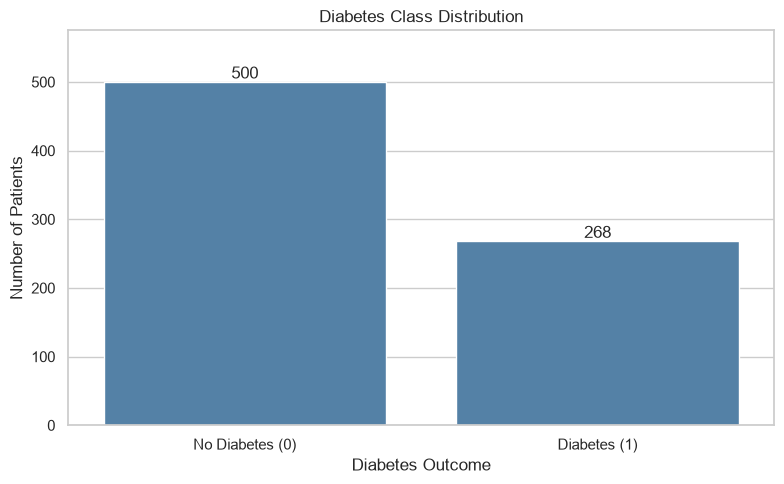

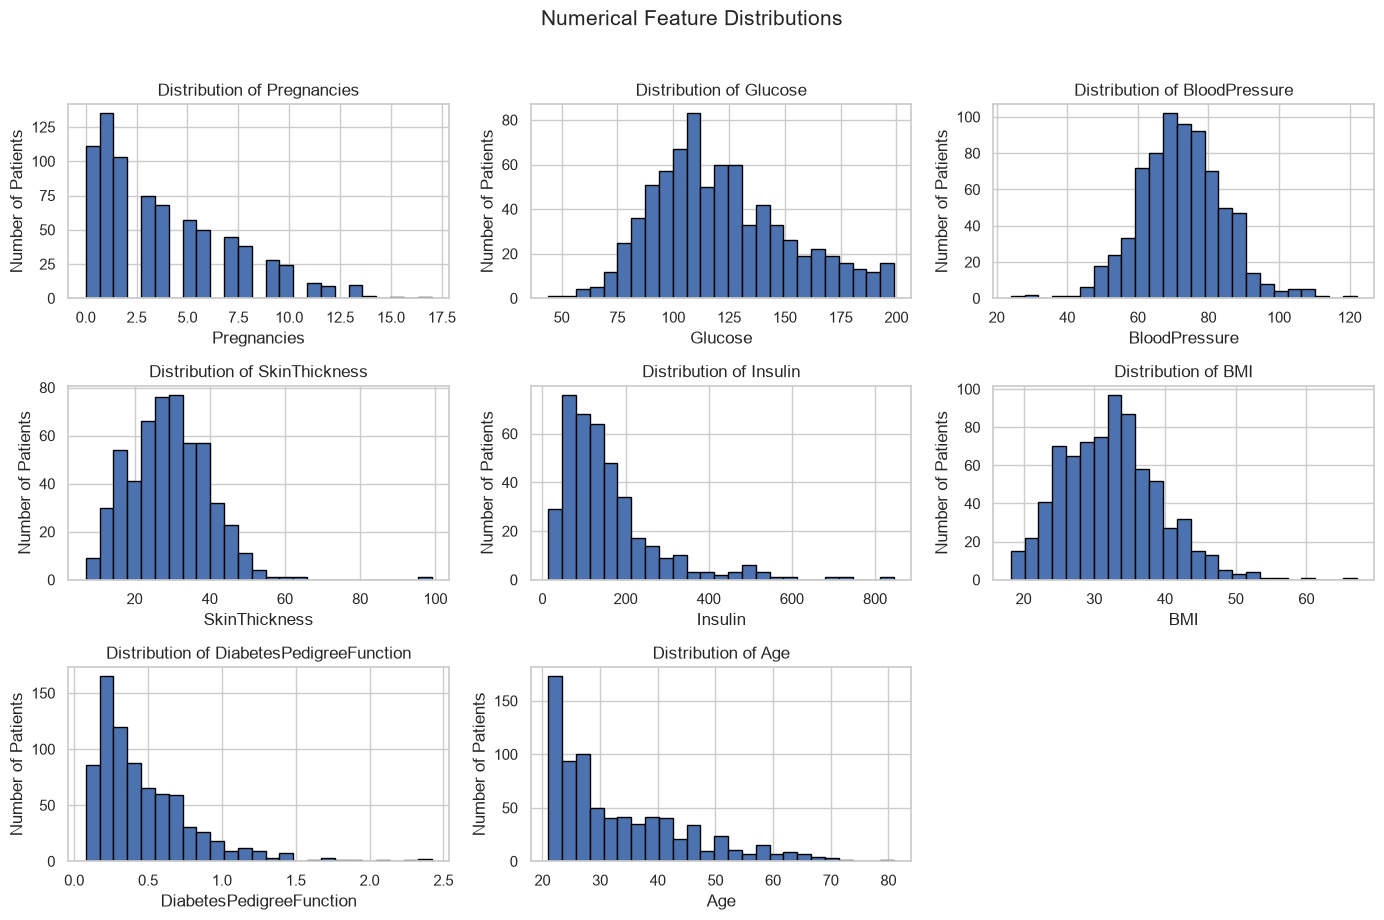

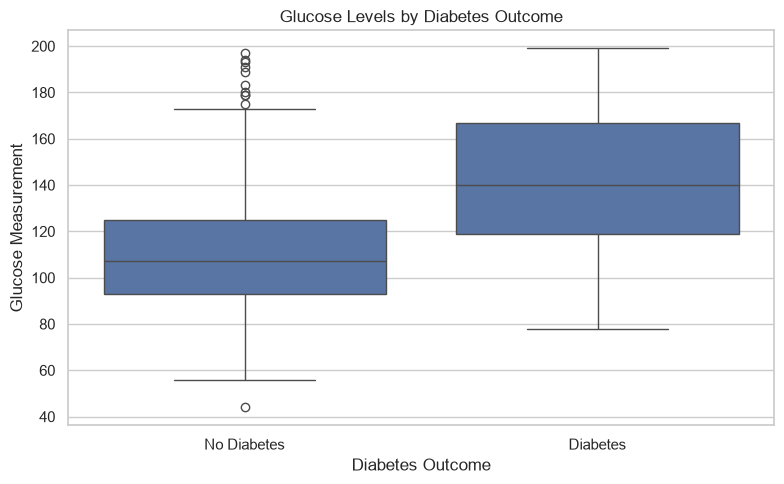

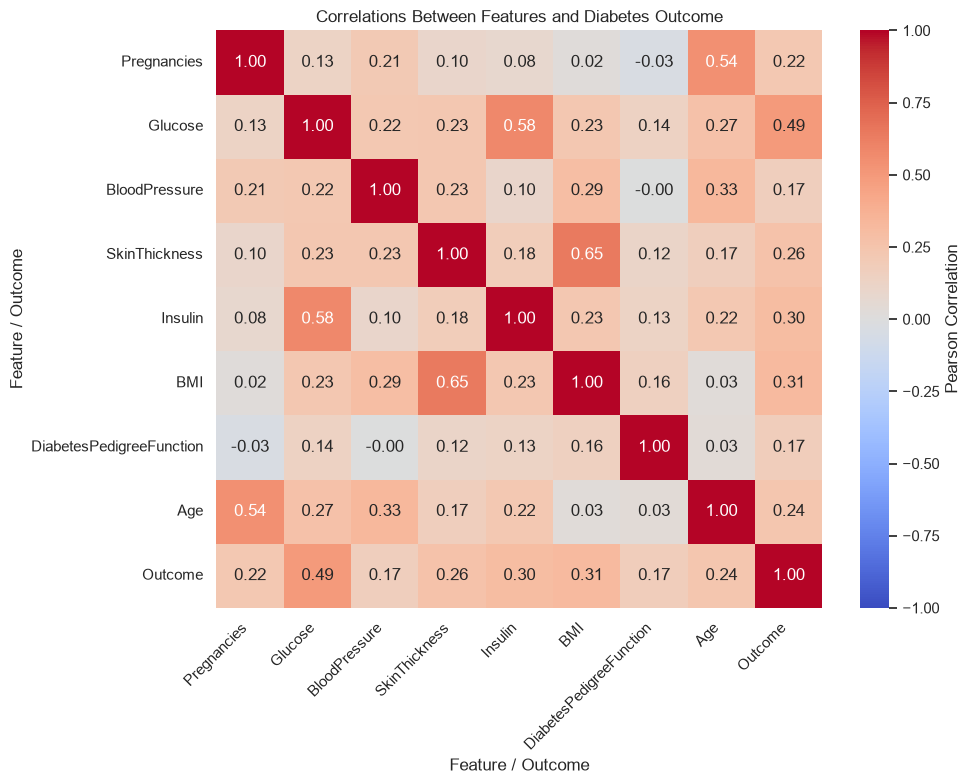

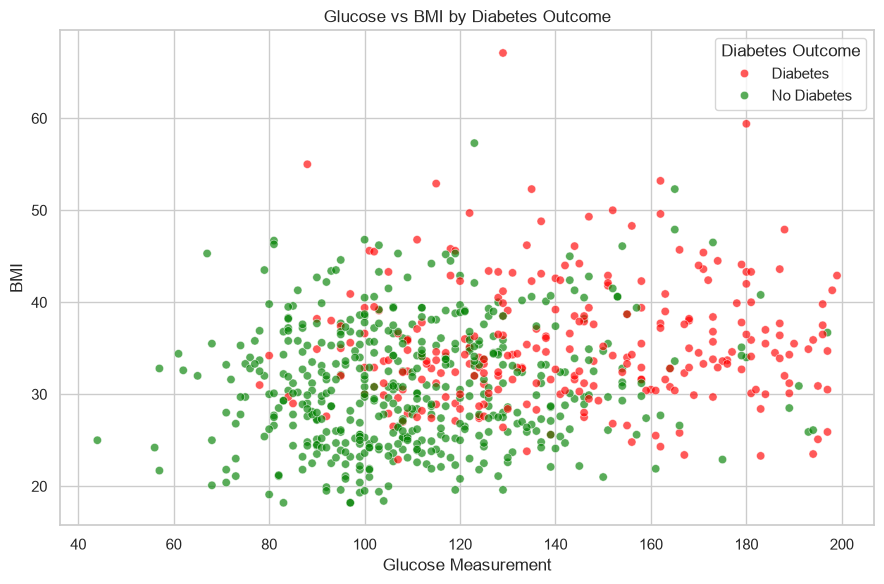


Training and testing split:
 Dataset  Patients  Percentage
Training       614       79.95
 Testing       154       20.05

Training class distribution:
Outcome
0    400
1    214

Testing class distribution:
Outcome
0    100
1     54

Training medians used for missing values:
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00

Missing values before and after imputation:
                          Before Imputation  After Imputation
Feature                                                      
Pregnancies                               0                 0
Glucose                                   4                 0
BloodPressure                            23                 0
SkinThickness                           175                 0
Insulin                    

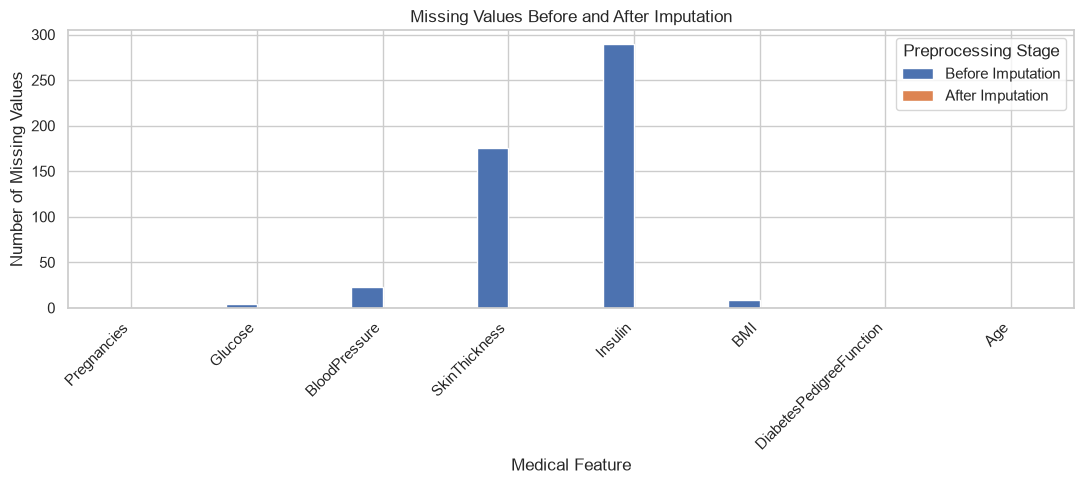


Remaining missing values: 0

Best hyperparameters:
{'tree__class_weight': 'balanced', 'tree__criterion': 'gini', 'tree__max_depth': 5, 'tree__min_samples_leaf': 1}

Best cross-validation F1-score:
0.6614

Top 10 hyperparameter combinations:
Criterion Maximum Depth  Minimum Leaf Size Class Weight  CV F1  CV Accuracy  CV Balanced Accuracy
     gini             5                  1     balanced  0.661        0.718                 0.735
     gini             3                  1     balanced  0.658        0.697                 0.730
     gini             3                 10     balanced  0.653        0.689                 0.723
     gini             3                  5     balanced  0.652        0.687                 0.722
     gini             3                  3     balanced  0.650        0.687                 0.721
  entropy             3                  1     balanced  0.643        0.677                 0.715
  entropy             3                 10     balanced  0.642        0.

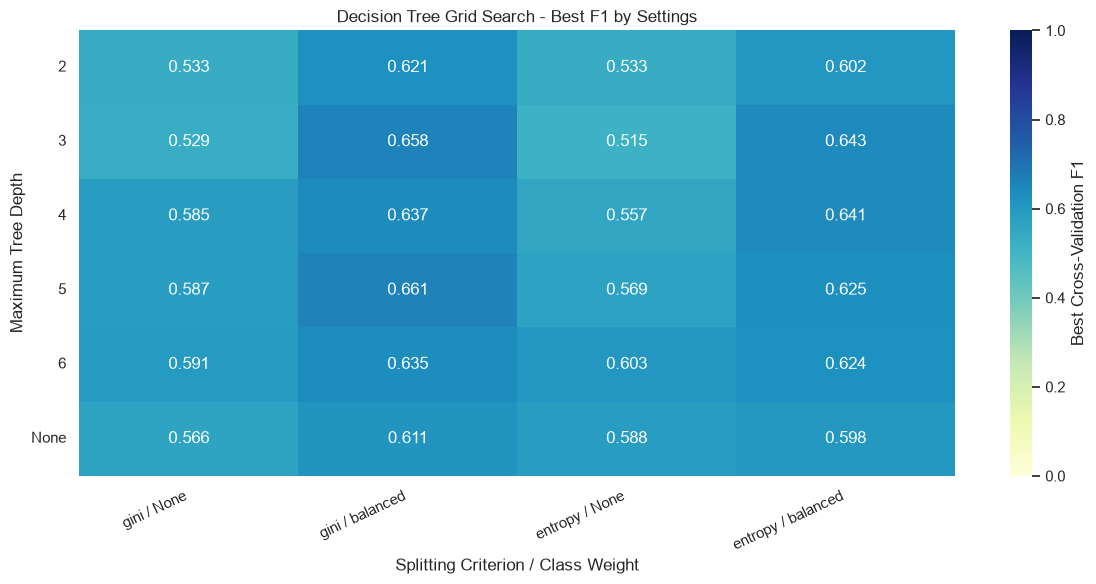


First 10 test predictions:
     Actual Outcome  Predicted Outcome  Correct
44                0                  1    False
672               0                  0     True
700               0                  0     True
630               1                  1     True
81                0                  0     True
389               0                  0     True
387               1                  0    False
408               1                  1     True
163               0                  0     True
335               0                  1    False

Correct predictions: 112
Incorrect predictions: 42

Final test results:
   Metric  Score
 Accuracy 0.7273
Precision 0.6111
   Recall 0.6111
       F1 0.6111

Classification report:
              precision    recall  f1-score   support

 No Diabetes       0.79      0.79      0.79       100
    Diabetes       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70 

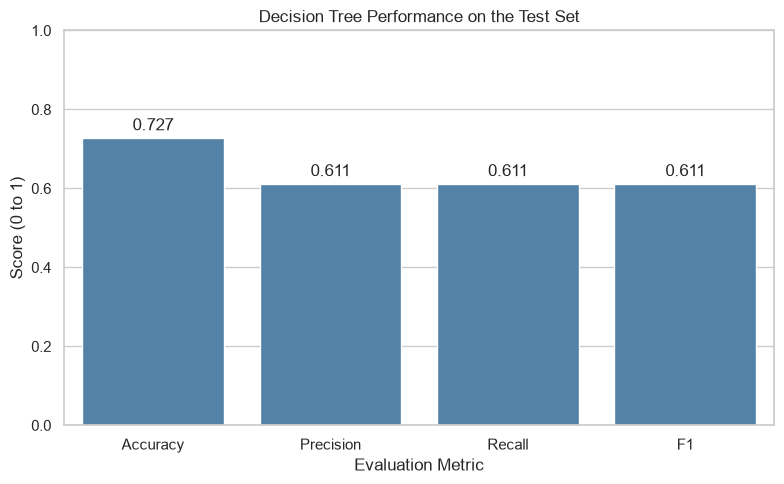

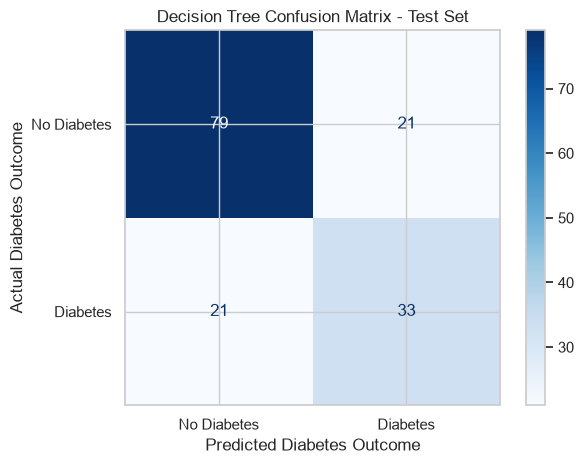


Decision Tree feature importances:
Glucose                     0.4710
BMI                         0.1957
Age                         0.1087
Insulin                     0.0803
DiabetesPedigreeFunction    0.0773
SkinThickness               0.0356
Pregnancies                 0.0314
BloodPressure               0.0000


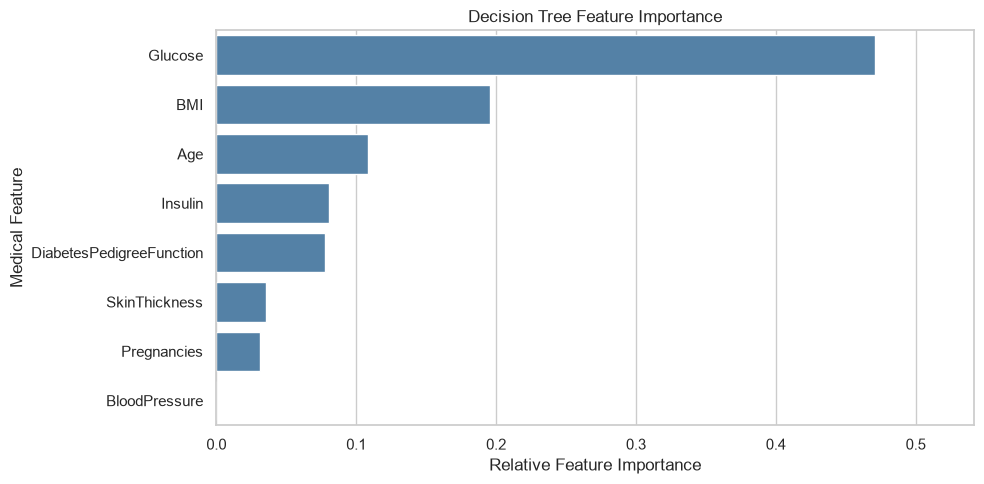

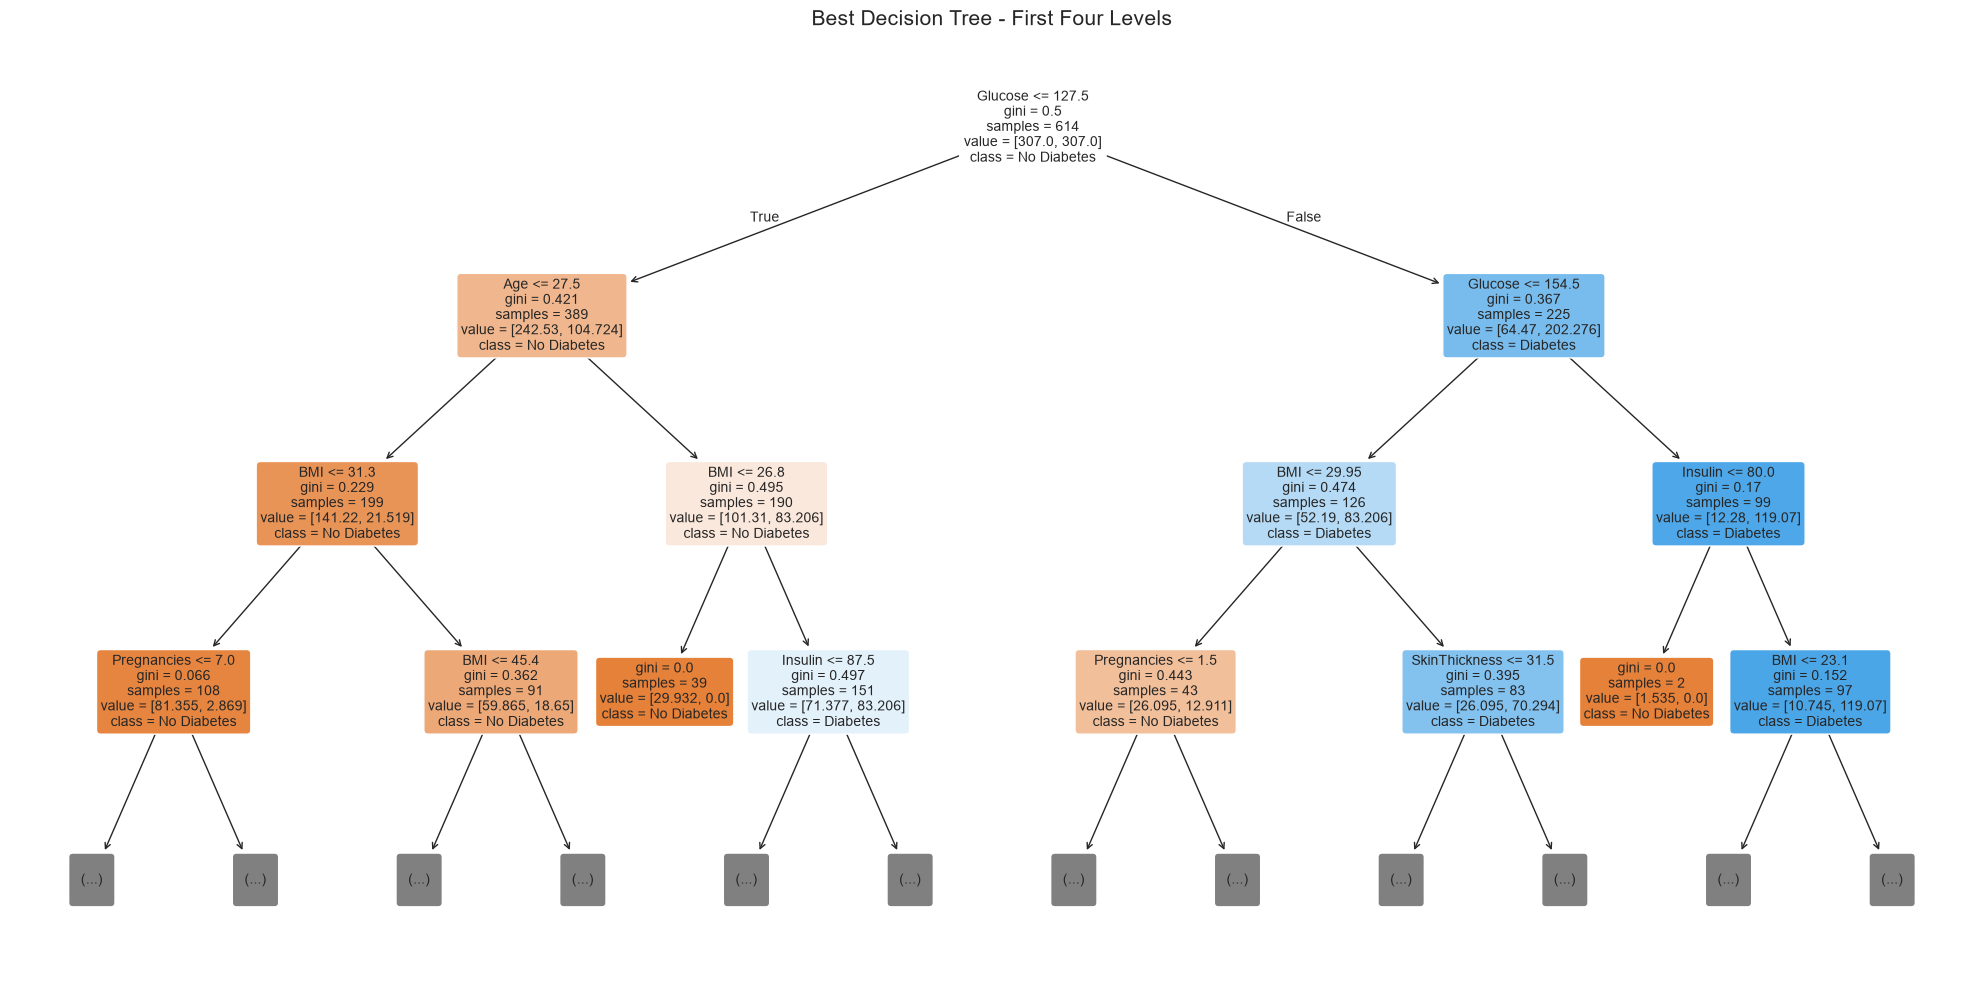


Summary:
Best parameters: {'tree__class_weight': 'balanced', 'tree__criterion': 'gini', 'tree__max_depth': 5, 'tree__min_samples_leaf': 1}
CV F1-score: 0.6614
Test accuracy: 0.7273
Test F1 (diabetes): 0.6111
Test recall (diabetes): 0.6111
Test precision (diabetes): 0.6111
Majority-class accuracy: 0.6494


In [ ]:
# Student: Gleb Matyushev
# Student ID: 12552707
# Group: Whales
# Dataset: Pima Indians Diabetes
# Algorithm: Decision Tree

# I used F1-score to select the best model because there are fewer
# diabetes cases than non-diabetes cases in the dataset.
# Accuracy alone could be misleading if the model misses many positive cases.


# ---------------------------------------------------------
# 1. Imports
# ---------------------------------------------------------

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")


# ---------------------------------------------------------
# 2. Load dataset
# ---------------------------------------------------------

# Look for the dataset in the current folder or its project subfolder
data_path = Path.cwd() / "data" / "diabetes.csv"

if not data_path.is_file():
    data_path = Path.cwd() / "02_Pima_Diabetes_Decision_Tree" / "data" / "diabetes.csv"

if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

# The CSV has no header, so we assign the column names
df = pd.read_csv(data_path, header=None, names=column_names)

print("\nDataset shape (rows, columns):", df.shape)

print("\nFirst 5 rows:")
print(df.head().to_string(index=False))


# ---------------------------------------------------------
# 3. Data inspection and preprocessing setup
# ---------------------------------------------------------

# X contains the 8 input features
# y contains the correct labels: 0 = no diabetes, 1 = diabetes
X = df.drop(columns="Outcome")
y = df["Outcome"]

print("\nDataset information:")
print("Patients:", len(df))
print("Input features:", X.shape[1])
print("Missing values in original file:", X.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Count patients in both classes
class_distribution = y.value_counts().sort_index()

class_summary = pd.DataFrame(
    {
        "Outcome": ["No Diabetes (0)", "Diabetes (1)"],
        "Patients": class_distribution.values,
        "Percentage": (class_distribution.values / len(df) * 100).round(2),
    }
)

print("\nClass distribution:")
print(class_summary.to_string(index=False))


# Zero pregnancies are possible, but zero is not a valid
# measurement for the following medical features
missing_zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Count invalid zero measurements
zero_counts = (X[missing_zero_columns] == 0).sum()

print("\nInvalid zero measurements:")
print(zero_counts.rename("Number of Zeros").to_string())

# Mark invalid zeros as missing
# np.nan represents a missing numerical value
# No medians are calculated at this point
X[missing_zero_columns] = X[missing_zero_columns].replace(0, np.nan)

print("\nMissing values after cleaning:")
print(X.isna().sum().rename("Missing Values").to_string())


# Define preprocessing, but do not fit it yet
# The medians will be calculated using training data only
imputer = SimpleImputer(strategy="median")

# A Decision Tree does not need StandardScaler because it uses value thresholds
model = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeClassifier(random_state=42)),
    ]
)


# ---------------------------------------------------------
# 4. Exploratory data analysis
# ---------------------------------------------------------

# Class distribution

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["No Diabetes (0)", "Diabetes (1)"],
    y=class_distribution.values,
    color="steelblue",
)

plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes Outcome")
plt.ylabel("Number of Patients")

# Show the number of patients above each bar
for i, count in enumerate(class_distribution.values):
    plt.text(i, count + 5, str(count), ha="center")

plt.ylim(0, class_distribution.max() * 1.15)
plt.tight_layout()
plt.show()


# Numerical feature distributions

# bins=25 divides the measurements into 25 intervals
hist_axes = X.hist(figsize=(14, 9), bins=25, edgecolor="black")

# Give every histogram its own title and axis labels
for ax, feature in zip(hist_axes.flat, X.columns):
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Patients")

plt.suptitle("Numerical Feature Distributions", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


# Compare glucose measurements between both classes

# Make a copy and use readable labels for plotting
plot_data = X.copy()
plot_data["Outcome"] = y.map({0: "No Diabetes", 1: "Diabetes"})

plt.figure(figsize=(8, 5))

sns.boxplot(data=plot_data, x="Outcome", y="Glucose", order=["No Diabetes", "Diabetes"])

# The line inside each box represents the median
# The box covers the middle 50% of values
plt.title("Glucose Levels by Diabetes Outcome")
plt.xlabel("Diabetes Outcome")
plt.ylabel("Glucose Measurement")
plt.tight_layout()
plt.show()


# Correlations between features and the outcome

# corr() calculates Pearson correlations
# assign() temporarily adds the target to the table
correlation_matrix = X.assign(Outcome=y).corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson Correlation"},
)

plt.title("Correlations Between Features and Diabetes Outcome")
plt.xlabel("Feature / Outcome")
plt.ylabel("Feature / Outcome")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# Glucose and BMI colored by outcome

# Each point represents one patient
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_data,
    x="Glucose",
    y="BMI",
    hue="Outcome",
    palette={"No Diabetes": "green", "Diabetes": "red"},
    alpha=0.65,
)

plt.title("Glucose vs BMI by Diabetes Outcome")
plt.xlabel("Glucose Measurement")
plt.ylabel("BMI")
plt.legend(title="Diabetes Outcome")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 5. Train/test split
# ---------------------------------------------------------

# Split the dataset before fitting the imputer
# 80% is used for training, 20% for final testing
# random_state=42 makes the split reproducible
# stratify=y keeps similar class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

split_summary = pd.DataFrame(
    {
        "Dataset": ["Training", "Testing"],
        "Patients": [len(X_train), len(X_test)],
        "Percentage": [len(X_train) / len(X) * 100, len(X_test) / len(X) * 100],
    }
)

print("\nTraining and testing split:")
print(split_summary.round(2).to_string(index=False))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index().rename("Patients").to_string())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index().rename("Patients").to_string())


# ---------------------------------------------------------
# 6. Check preprocessing
# ---------------------------------------------------------

# Fit the imputer using training data only
# fit_transform calculates medians and replaces missing values
# This is only for checking preprocessing
# GridSearchCV will fit its own imputer inside each fold
X_train_processed = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)

# statistics_ contains the median learned from each training column
median_values = pd.Series(
    imputer.statistics_, index=X_train.columns, name="Training Median"
)

print("\nTraining medians used for missing values:")
print(median_values.round(2).to_string())


# Compare missing values before and after imputation
missing_summary = pd.DataFrame(
    {
        "Before Imputation": X_train.isna().sum(),
        "After Imputation": X_train_processed.isna().sum(),
    }
)

missing_summary.index.name = "Feature"

print("\nMissing values before and after imputation:")
print(missing_summary.to_string())

ax = missing_summary.plot.bar(figsize=(11, 5))

ax.set_title("Missing Values Before and After Imputation")
ax.set_xlabel("Medical Feature")
ax.set_ylabel("Number of Missing Values")
ax.legend(title="Preprocessing Stage")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nRemaining missing values:", X_train_processed.isna().sum().sum())


# ---------------------------------------------------------
# 7. Decision Tree training and Grid Search
# ---------------------------------------------------------

# tree__ means the parameter belongs to the "tree" step of the pipeline
# criterion measures the quality of a split
# max_depth limits how deep the tree can grow
# None means no explicit depth limit
# min_samples_leaf sets the minimum number of samples in a leaf
# class_weight="balanced" gives more weight to the smaller class
param_grid = {
    "tree__criterion": ["gini", "entropy"],
    "tree__max_depth": [2, 3, 4, 5, 6, None],
    "tree__min_samples_leaf": [1, 3, 5, 10],
    "tree__class_weight": [None, "balanced"],
}

# Use 5-fold cross-validation
# Each fold has approximately the same ratio of both classes
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Built-in sklearn scoring names
# f1 evaluates class 1 (diabetes) as the positive class
scoring = {"accuracy": "accuracy", "f1": "f1", "balanced_accuracy": "balanced_accuracy"}

# GridSearchCV tries all combinations using the training folds
# refit="f1" selects the model with the best average validation F1
# n_jobs=-1 uses all available CPU cores
grid_search = GridSearchCV(
    model, param_grid, scoring=scoring, refit="f1", cv=cv, n_jobs=-1
)

# Only training data is used during Grid Search
# The imputer is fitted separately inside every fold
grid_search.fit(X_train, y_train)

print("\nBest hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))


# Grid Search results

# cv_results_ contains the parameters and scores from every combination
cv_results = pd.DataFrame(grid_search.cv_results_)

best_results = cv_results[
    [
        "param_tree__criterion",
        "param_tree__max_depth",
        "param_tree__min_samples_leaf",
        "param_tree__class_weight",
        "mean_test_f1",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
    ]
].sort_values("mean_test_f1", ascending=False)

best_results = best_results.rename(
    columns={
        "param_tree__criterion": "Criterion",
        "param_tree__max_depth": "Maximum Depth",
        "param_tree__min_samples_leaf": "Minimum Leaf Size",
        "param_tree__class_weight": "Class Weight",
        "mean_test_f1": "CV F1",
        "mean_test_accuracy": "CV Accuracy",
        "mean_test_balanced_accuracy": "CV Balanced Accuracy",
    }
)

print("\nTop 10 hyperparameter combinations:")
print(best_results.head(10).round(3).to_string(index=False))


# Grid Search heatmap

# Convert parameter values into readable labels
# None is stored as a missing value in some versions of Pandas
cv_results["depth"] = cv_results["param_tree__max_depth"].apply(
    lambda value: "None" if pd.isna(value) else str(value)
)

cv_results["weight_label"] = cv_results["param_tree__class_weight"].apply(
    lambda value: "None" if pd.isna(value) else str(value)
)

cv_results["settings"] = (
    cv_results["param_tree__criterion"].astype(str) + " / " + cv_results["weight_label"]
)

# Each heatmap cell shows the highest CV F1 for that depth and setting
# The best min_samples_leaf is selected within each cell
heatmap_data = cv_results.pivot_table(
    index="depth", columns="settings", values="mean_test_f1", aggfunc="max"
)

heatmap_data = heatmap_data.reindex(
    index=["2", "3", "4", "5", "6", "None"],
    columns=["gini / None", "gini / balanced", "entropy / None", "entropy / balanced"],
)

# Check whether all expected settings have results
if heatmap_data.isna().any().any():
    print("\nWarning: Some heatmap values are missing.")
    print(heatmap_data)

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Best Cross-Validation F1"},
)

plt.title("Decision Tree Grid Search - Best F1 by Settings")
plt.xlabel("Splitting Criterion / Class Weight")
plt.ylabel("Maximum Tree Depth")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 8. Predictions
# ---------------------------------------------------------

# best_estimator_ is the selected pipeline
# GridSearchCV has already retrained it on all training observations
best_model = grid_search.best_estimator_

# Predict the labels of the test patients
# The pipeline also applies the fitted imputer to the test features
y_pred = best_model.predict(X_test)

# Compare actual and predicted classes
predictions = pd.DataFrame(
    {"Actual Outcome": y_test, "Predicted Outcome": y_pred}, index=X_test.index
)

predictions["Correct"] = (
    predictions["Actual Outcome"] == predictions["Predicted Outcome"]
)

print("\nFirst 10 test predictions:")
print(predictions.head(10).to_string())

print("\nCorrect predictions:", predictions["Correct"].sum())
print("Incorrect predictions:", (~predictions["Correct"]).sum())


# ---------------------------------------------------------
# 9. Evaluation and summary
# ---------------------------------------------------------

# y_test contains the actual classes, y_pred contains predictions
# pos_label=1 means that we evaluate the diabetes class
# Accuracy = correctly predicted patients / all patients
# Precision = correctly predicted positive patients / predicted positives
# Recall = correctly predicted positive patients / actual positives
# F1 combines precision and recall
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1"],
        "Score": [accuracy, precision, recall, f1],
    }
)

print("\nFinal test results:")
print(metrics.round(4).to_string(index=False))

print("\nClassification report:")
print(
    classification_report(
        y_test, y_pred, labels=[0, 1], target_names=["No Diabetes", "Diabetes"]
    )
)


# Majority-class baseline

# DummyClassifier always predicts the most common training class
# This shows the accuracy without using the medical features
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_accuracy = baseline.score(X_test, y_test)

print("\nMajority-class baseline accuracy:", round(baseline_accuracy, 4))


# Evaluation metrics plot

plt.figure(figsize=(8, 5))

sns.barplot(data=metrics, x="Metric", y="Score", color="steelblue")

plt.title("Decision Tree Performance on the Test Set")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (0 to 1)")
plt.ylim(0, 1)

# Display the score above every bar
for i, score in enumerate(metrics["Score"]):
    plt.text(i, score + 0.02, f"{score:.3f}", ha="center")

plt.tight_layout()
plt.show()


# Confusion matrix

# Rows are actual classes, columns are predicted classes
# The numbers show how many patients belong to each combination
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues",
    values_format="d",
)

cm_display.ax_.set_xlabel("Predicted Diabetes Outcome")
cm_display.ax_.set_ylabel("Actual Diabetes Outcome")

plt.title("Decision Tree Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()


# Feature importance

# named_steps["tree"] gets the trained Decision Tree from the pipeline
# feature_importances_ shows the contribution to reducing impurity
importances = pd.Series(
    best_model.named_steps["tree"].feature_importances_,
    index=X.columns,
    name="Importance",
).sort_values(ascending=False)

print("\nDecision Tree feature importances:")
print(importances.round(4).to_string())

plt.figure(figsize=(10, 5))

sns.barplot(x=importances.values, y=importances.index, color="steelblue")

plt.title("Decision Tree Feature Importance")
plt.xlabel("Relative Feature Importance")
plt.ylabel("Medical Feature")
plt.xlim(0, max(0.05, importances.max() * 1.15))
plt.tight_layout()
plt.show()


# Decision Tree visualization

# max_depth=3 shows only the first four levels of the trained tree
# It does not change the trained model itself
plt.figure(figsize=(20, 10))

plot_tree(
    best_model.named_steps["tree"],
    feature_names=X.columns.tolist(),
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3,
)

plt.title("Best Decision Tree - First Four Levels", fontsize=15)
plt.tight_layout()
plt.show()


# Summary

# F1 was used to select the model because diabetes is the smaller class
# Accuracy alone would not show how many positive cases were missed
print("\nSummary:")
print("Best parameters:", grid_search.best_params_)
print("CV F1-score:", round(grid_search.best_score_, 4))
print("Test accuracy:", round(accuracy, 4))
print("Test F1 (diabetes):", round(f1, 4))
print("Test recall (diabetes):", round(recall, 4))
print("Test precision (diabetes):", round(precision, 4))
print("Majority-class accuracy:", round(baseline_accuracy, 4))